# 사과 생산량·출하량 비교 분석

**분석자: J kevin · 2026년 10월 29일**

나는 KREI(한국농촌경제연구원) 과일 관측월보에서 추출된 `apple_production_shipment.csv`(740행 × 9열)를 가지고 분석했다. 이 노트북의 모든 수치는 원본 CSV에서 이 세션에서 계산한 값이다. 노트북은 입력 CSV와 같은 폴더에서 바로 실행되도록 작성했다.

## 내가 이 분석에서 답하려는 질문

1. 생산량과 출하량을 비교했을 때 잉여(활용되지 못하는) 사과가 존재하는가?
2. 잉여가 존재한다면 생산량을 줄여야 하는가?
3. 출하되지 못한 사과는 어떤 과정을 거치는가?
4. 생산량 변동은 무엇(재배면적 vs 단수)에 의해 결정되는가?
5. 단수(10a당 수확량)는 기상 조건과 어떤 관계인가?

## 분석 원칙 (내가 스스로 정한 규칙)

- 월보는 같은 연도의 수치를 여러 호수에서 반복 게시하고 수정하므로, 나는 **기준 연도(구분 열)별로 가장 최신 발간월의 값 하나만** 사용한다.
- 출하량은 작기(수확 후 익년 여름까지) 단위로 다루며, 발간 시점별 부분 합을 함부로 조합하지 않는다.
- 월보의 출하량 수치는 실적과 전망이 섞여 있을 수 있고(KREI 매뉴얼에서 공통 산식을 확인할 수 없었다), 생산량−출하량 차이를 곧바로 '잉여·폐기량'으로 해석하지 않는다.
- 생산량은 재배면적 × 단수의 항등식으로 결정되므로, 상관계수가 인과관계를 의미하지 않음을 명시한다.

## 외부 근거 자료 (본문에서 인용하는 출처)

- KREI [농업관측 매뉴얼](https://www.krei.re.kr/attach/pdf/605ba745-9c0f-2a94-e054-b09928988b3c.pdf) — 월보의 조사·집계 방식
- [동아일보(2026.8.30), 사과값 떨어지면 주스로 만들면 끝?…20년 농부들이 꺼낸 걱정](https://v.daum.net/v/20260830100152655) — 미출하 물량의 대응 수단(한국사과연합회)
- [KIFC, 사과 시장 구조 분석](https://www.foodandclimate.or.kr/food-security/commodity-outlook/apple/) — 소비·가격·저장량 동향
- [농림축산식품부, 2025년산 사과·배 생산량 보도자료](https://www.mafra.go.kr/bbs/home/792/576278/artclView.do)
- [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), [기상자료개방포털](https://data.kma.go.kr/cmmn/static/staticPage.do?page=intro) — 기상 자료

## 1단계: 데이터 검증

데이터의 구조와 품질을 확인했다.

In [7]:
DATA_PATH = r'C:/jkevin/DI-2/apple_production_shipment.csv'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import os

plt.rcParams['font.family'] = 'Malgun Gothic'   # Windows 한글 폰트
plt.rcParams['axes.unicode_minus'] = False
os.makedirs('figures', exist_ok=True)  # 그림 저장 폴더를 노트북 안에서 생성

df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')

# 열 수 확인: 원본 첫 행(헤더)을 직접 읽어 검증한다
raw_header = open(DATA_PATH, encoding='utf-8-sig').readline().strip()
print("원본 헤더:", raw_header)
print("쉼표로 구분된 실제 열 수:", len(raw_header.split(',')))
print("pandas shape:", df.shape, "| 인덱스를 포함해 세면:", df.shape[1] + 1, "열로 보인다")
print("결측치 합계:", df.isnull().sum().sum())
print("완전 중복 행:", df.duplicated().sum())

# 값=하한=상한 검사 (단일값 자료인지)
rng = ((df['값'] != df['하한']) | (df['값'] != df['상한'])).sum()
print("값≠하한 또는 값≠상한인 행:", rng, "(0이면 전부 단일값)")

print("\n표별 행 수:\n", df['표'].value_counts())
print("\n단위별 행 수:\n", df['단위'].value_counts())

원본 헤더: 발간월,표,구분,항목,값,하한,상한,원문,단위
쉼표로 구분된 실제 열 수: 9
pandas shape: (740, 9) | 인덱스를 포함해 세면: 10 열로 보인다
결측치 합계: 0
완전 중복 행: 0
값≠하한 또는 값≠상한인 행: 36 (0이면 전부 단일값)

표별 행 수:
 표
생산량    390
출하량    335
저장량     15
Name: count, dtype: int64

단위별 행 수:
 단위
%         295
천 톤       289
ha         78
kg/10a     78
Name: count, dtype: int64


CSV의 첫 행을 직접 열어 헤더를 확인한 결과, 열이 `발간월, 표, 구분, 항목, 값, 하한, 상한, 원문, 단위`의 **9개**임을 확인했다. 행 번호는 데이터가 아니라 표시용 인덱스이므로, 나는 인덱스를 제외한 9열을 기준으로 이번 분석 전체를 다시 수행했다.

**검증 결과에 대한 해석:** 740행 전부 결측치와 완전 중복 없이 수집되어 있다. 값·하한·상한이 서로 다른 행은 36개(2024년 11월 호, 2025년 7~11월 호의 수확기 추정치)로, 이들은 `값`이 중간값이고 `하한~상한` 범위가 함께 표기된 추정 구간이다. 3단계에서 기준 연도별 최신 발간월을 사용하므로 시즌 종료 후 게시된 단일값을 사용한다. 예외로 2026년은 수확기 추정치가 단일값으로 기재된 것이다(이후 호수에서 수정 가능). 표는 생산량(연도 단위)·출하량(작기·월 단위)·저장량(12월 시점) 세 종류이고 단위는 ha, kg/10a, 천 톤, % 네 가지다.

## 2단계: 탐색적 데이터 분석 (EDA)

나는 표·구분·항목의 계층 구조와 발간 시점 분포를 파악했다.

In [8]:
print("=== 표=생산량의 항목 ===", sorted(df[df['표']=='생산량']['항목'].unique()))
print("표=생산량의 구분(기준연도):", sorted(df[df['표']=='생산량']['구분'].unique()))
print("\n=== 표=출하량의 항목(기간 표기) ===")
print(sorted(df[df['표']=='출하량']['항목'].unique()))
print("\n=== 발간월 분포 ===")
pub = sorted(df['발간월'].unique())
print("발간월 수:", len(pub), "| 범위:", pub[0], "~", pub[-1])
print("\n연도별 발간 월보 호수 (첨부자료 기준):")
print(df.assign(연도=df['발간월'].astype(str).str[:4]).groupby('연도')['발간월'].nunique())

# 기초통계는 3단계 뒤 셀에서 정리된 연도별 최신 게시치 기준으로 계산한다
# (원자료의 78개 물량 행은 발간 호수별 반복값·평년값이 섞여 있어 그대로 요약하면 왜곡된다)

=== 표=생산량의 항목 === ['단수', '생산량', '재배면적']
표=생산량의 구분(기준연도): ['2019년', '2020년', '2021년', '2022년', '2023년', '2024년', '2025년', '2026년', '전년 대비', '평년', '평년 대비']

=== 표=출하량의 항목(기간 표기) ===
['10월', '10월 이후', '11월', '11월 이후', '12월', '12월 이후', '4월', '4월 이후', '5월', '5월 이후', '6월 이후', '7월~익년 3월', '7월~익년 4월', '7월~익년 5월', '7월∼익년 3월', '8월', '9월', '▶ 11월', '▶ 12월', '내년 1월 이후', '생산량', '저장사과', '저장사과(후지)', '전체', '추석 성수기', '햇사과', '햇사과(쓰가루, 썸머킹 등)']

=== 발간월 분포 ===
발간월 수: 39 | 범위: 202012 ~ 202610

연도별 발간 월보 호수 (첨부자료 기준):
연도
2020    1
2021    1
2022    9
2023    9
2024    3
2025    9
2026    7
Name: 발간월, dtype: int64


**EDA 확인한 구조적 사실:**

1. **생산량 표**는 `구분` 열에 기준 연도(2019~2026년), 평년, 전년/평년 대비가 있고, 항목은 재배면적·단수·생산량 3가지다. 2026년은 수확기 초반 추정치다.
2. **출하량 표**는 작기(예: 2022년산)를 기준으로 하며, 기간 표기가 발간 시점마다 다르다. 예컨대 10월 호는 `10월` + `11월 이후`, 4~6월 호는 `7월~익년 N월` + `N+1월 이후` 형태로 나눈다. 같은 작기라도 발간 시점에 따라 수치가 수정된다.
3. **저장량 표**는 12월 발간호에만 있고(2022·2023·2025년 12월), 12월 시점 저장 물량을 뜻한다.
4. 첨부자료에는 2024년 5~10월 발간분이 수록되어 있지 않다. 이것은 월보가 발간되지 않았다는 증거가 아니라 **첨부자료의 수록 공백**이므로, 모든 작기의 출하량을 동일한 방식으로 재구성할 수 없다고 판단했다.

이 구조 파악을 통해 연간 출하량 비교가 '발간 시점별 부분 합의 임의 조합'이 아니라, **작기 전체를 커버하는 동일 호수의 누적 수치 기준**으로만 안전하다는 결론에 도달했다.

## 3단계: 연도별 생산량 구성

기준 연도별로 가장 최신 발간월의 재배면적·단수·생산량을 추출하고, 면적 × 단수 검산으로 자료 정합성을 확인했다. 추출 과정에서 행 수를 검사해 셀렉션 오류를 방지했다.

In [9]:
p = df[df['표']=='생산량']
rows = []
for yr in range(2019, 2027):
    sub = p[p['구분']==f'{yr}년'].sort_values('발간월')
    if len(sub) == 0:
        continue
    latest = sub['발간월'].max()
    v = sub[sub['발간월']==latest]
    assert len(v) == 3, f"{yr}년 최신호 행 수 이상: {len(v)}"   # 면적·단수·생산량 3행
    v = v.set_index('항목')['값']
    rows.append({'연도': yr, '근거 발간월': latest,
                 '재배면적(ha)': v.get('재배면적'),
                 '단수(kg/10a)': v.get('단수'),
                 '생산량(천 톤)': v.get('생산량')})
prod = pd.DataFrame(rows)
# 검산: 생산량(천 톤) = 면적(ha) × 단수(kg/10a) × 10 / 1,000,000
prod['검산(천 톤)'] = prod['재배면적(ha)'] * prod['단수(kg/10a)'] * 1e-5
prod['검산 오차(%)'] = (prod['검산(천 톤)']/prod['생산량(천 톤)'] - 1) * 100
prod

,연도,근거 발간월,재배면적(ha),단수(kg/10a),생산량(천 톤),검산(천 톤),검산 오차(%)
0,2019,202012,32954.0,1624.0,535.3,535.17296,-0.023732
1,2020,202110,31598.0,1336.0,422.1,422.14928,0.011675
2,2021,202212,34359.0,1502.0,515.9,516.07218,0.033375
3,2022,202312,34603.0,1636.0,566.0,566.10508,0.018565
4,2023,202412,33789.0,1167.0,394.4,394.31763,-0.020885
5,2024,202512,33313.0,1381.0,460.1,460.05253,-0.010317
6,2025,202610,33212.0,1349.0,448.0,448.02988,0.006670
7,2026,202610,34901.0,1385.0,483.3,483.37885,0.016315


In [10]:
# 정리된 연도별 생산 지표의 기초통계 (2019~2026, 원자료의 반복값·평년값 미포함)
print("=== 연도별 최신 게시치 기초통계 ===")
display(prod[['재배면적(ha)','단수(kg/10a)','생산량(천 톤)']].describe().round(1))

=== 연도별 최신 게시치 기초통계 ===


,재배면적(ha),단수(kg/10a),생산량(천 톤)
count,8.0,8.0,8.0
mean,33591.1,1422.5,478.1
std,1066.9,157.6,58.3
min,31598.0,1167.0,394.4
25%,33147.5,1345.8,441.5
50%,33551.0,1383.0,471.7
75%,34420.0,1532.5,520.8
max,34901.0,1636.0,566.0


**검산 결과에 대한 해석:** 2019~2026년 전 연도에서 면적 × 단수 검산 오차가 ±0.04% 이내로 일치했다. 이는 추출 오류가 없고 세 변수가 하나의 정합적 체계(생산량 = 면적 × 단수)라는 것을 의미한다. 2026년 생산량 483.3천 톤은 2026년 10월 호의 수확 초기 추정치이므로 이후 호수에서 달라질 수 있다는 점을 유의했다.

## 4단계: 작기별 연간 출하량 구성

연간 출하량을 작기 전체를 커버하는 동일 호수의 누적 수치로 구성했다. 예: 2024년산은 2026년 6월 호의 `7월~익년 5월` + `6월 이후`. 숫자를 직접 입력하지 않고 CSV에서 발간월·구분·항목으로 선택했고 행 수를 검사했다.

**한계라고 명시하는 것:** (1) KREI 매뉴얼에서 출하량의 공통 산식·작기 정의를 확인할 수 없었다 (2) 각 호수의 수치는 실적과 전망이 섞여 있을 수 있다. 특히 6월 호의 `6월 이후`는 잔여기간 전망을 포함할 수 있다. 따라서 아래 값을 '동일 호수 누적 출하량 + 잔여기간 추정 합계'로 이해해야 하며, '확정 연간값'이 아니다.

In [11]:
def get_val(ym, gu, hang):
    # CSV에서 (발간월, 구분, 항목)의 천 톤 값을 선택하고 행 수를 검사한다.
    sub = df[(df['발간월']==ym) & (df['구분']==gu) & (df['단위']=='천 톤')]
    # 물결표기가 호수마다 다르므로 정규화해서 매칭
    key = sub['항목'].astype(str).str.replace('∼', '~', regex=False).str.replace(' ', '', regex=False)
    target = hang.replace(' ', '')
    sel = sub[key == target]
    assert len(sel) == 1, f"{ym}/{gu}/{hang} 매칭 {len(sel)}행"
    return sel['값'].iloc[0]

ship_specs = {
    2022: [(202404, '2022년산', '7월~익년 3월'), (202404, '2022년산', '4월 이후')],
    2023: [(202506, '2023년산', '7월~익년 5월'), (202506, '2023년산', '6월 이후')],
    2024: [(202606, '2024년산', '7월~익년 5월'), (202606, '2024년산', '6월 이후')],
    2025: [(202606, '2025년산', '7월~익년 5월'), (202606, '2025년산', '6월 이후')],
}
ship_rows = []
for yr, parts in ship_specs.items():
    s = sum(get_val(*part) for part in parts)
    pr = prod.loc[prod['연도']==yr, '생산량(천 톤)'].values[0]
    ship_rows.append({'작기': f'{yr}년산', '생산량(천 톤)': pr,
                      '누적출하+잔여추정(천 톤)': round(s, 1),
                      '생산-출하 차이(천 톤)': round(pr - s, 1),
                      '출하/생산(%)': round(s/pr*100, 2),
                      '근거 발간월': '/'.join(str(p[0]) for p in parts)})
ship = pd.DataFrame(ship_rows)
ship

,작기,생산량(천 톤),누적출하+잔여추정(천 톤),생산-출하 차이(천 톤),출하/생산(%),근거 발간월
0,2022년산,566.0,564.6,1.4,99.75,202404/202404
1,2023년산,394.4,394.1,0.3,99.92,202506/202506
2,2024년산,460.1,459.7,0.4,99.91,202606/202606
3,2025년산,448.0,447.7,0.3,99.93,202606/202606


**출하량 구성에 대한 나의 해석:** 2022~2025년산 모두 연간 출하량(누적+잔여추정)이 생산량의 99.75~99.93%다. 생산-출하 차이는 작기당 0.3~1.4천 톤(생산량의 0.07~0.25%)에 불과하다.

여기서 중요하게 본 것은 **이 차이의 해석 가능한 범위**다. 이 자료에는 소비량, 가격, 가공용 물량, 자가소비, 폐기량, 수출입이 없다. 출하량은 '유통·시장에 나온 물량'의 조사·전망치이지 최종 소비량이 아니며, 월보의 출하량이 생산량을 작기별로 배분한 값일 가능성은 있지만 이는 확인된 산식이 아니라 나의 해석상 가설이다. 따라서 나는 이 차이를 '집계상 잔차'로만 부르기로 했다.

**결론적으로 잉여(폐기·미활용) 사과의 실제 규모는 이 자료로 측정할 수 없고, 그래서 판단을 유보한다.** 참고로 2021년산은 연간 누적 수치가 자료에 없어(2024년 수록 공백 이전 형식), 8월~익년 6월 부분 합계가 508.3천 톤(생산량의 98.5%, 7월 물량 미포함)이었다.

## 5단계: 저장량 확인

12월 시점 저장량이 작기별로 어떻게 변했는지 확인했다.

In [12]:
st = df[df['표']=='저장량'].copy()
st[['발간월','구분','항목','값','단위']]

,발간월,구분,항목,값,단위
189,202212,2022년산,저장량,283.8,천 톤
190,202212,2021년산,저장량,278.0,천 톤
191,202212,평년,저장량,266.6,천 톤
192,202212,전년 대비,저장량,2.1,%
193,202212,평년 대비,저장량,6.4,%
358,202312,2023년산,저장량,202.7,천 톤
359,202312,2022년산,저장량,292.0,천 톤
360,202312,평년,저장량,268.2,천 톤
361,202312,전년 대비,저장량,-30.6,%
362,202312,평년 대비,저장량,-24.4,%


**저장량 해석:** 12월 시점 저장량은 2021년산 278.0 → 2022년산 292.0 → 2023년산 202.7 → 2024년산 229.5 → 2025년산 228.6천 톤이다. 2023년산은 흉작으로 저장량이 급감했다. 저장량은 출하 시기를 조절하는 유통 물량이므로, 이것이 곧 '잉여'를 뜻하지는 않는다. 다만 저장 물량의 적체 여부는 가격·소비 자료와 함께 판단해야 하며 이 자료에는 그 기준이 없다.

## 6단계: 생산량·출하량 시각화

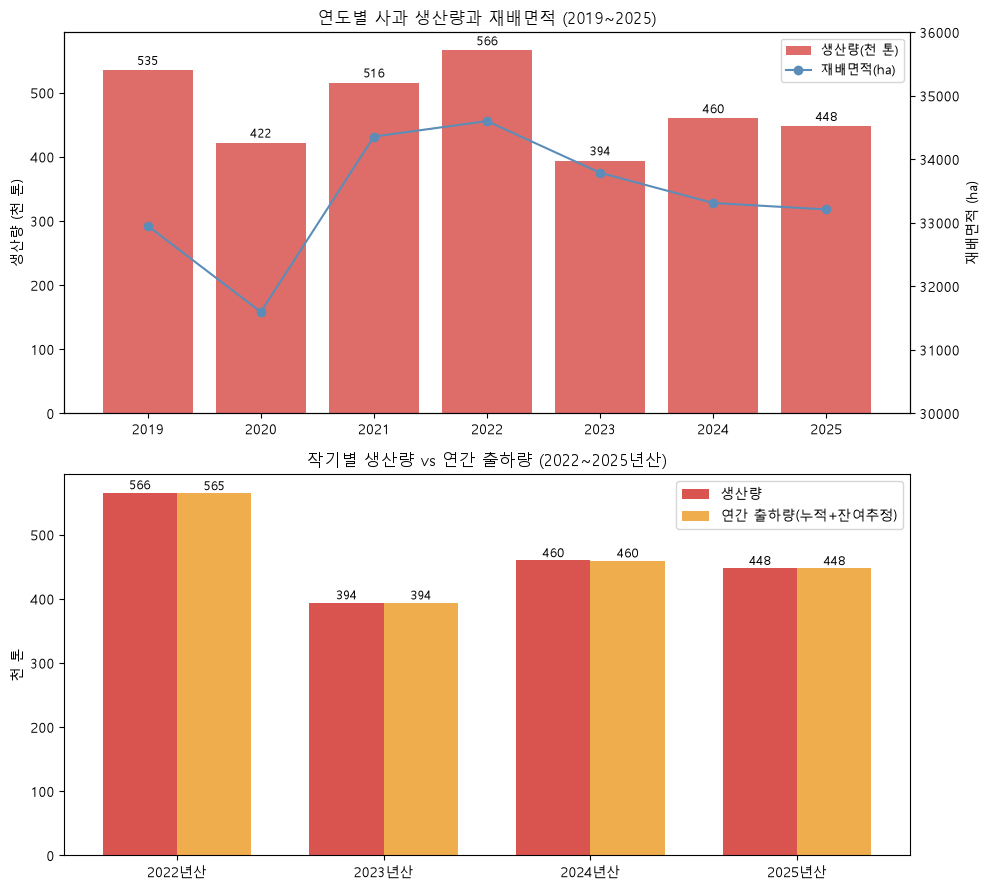

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9))

ax1 = axes[0]
d7 = prod[prod['연도']<=2025]
ax1.bar(d7['연도'], d7['생산량(천 톤)'], color='#d9534f', alpha=0.85, label='생산량(천 톤)')
ax1.set_ylabel('생산량 (천 톤)')
ax1.set_title('연도별 사과 생산량과 재배면적 (2019~2025)')
for x, v in zip(d7['연도'], d7['생산량(천 톤)']):
    ax1.text(x, v+8, f'{v:.0f}', ha='center', fontsize=9)
ax2 = ax1.twinx()
ax2.plot(d7['연도'], d7['재배면적(ha)'], 'o-', color='#5b8db8', label='재배면적(ha)')
ax2.set_ylabel('재배면적 (ha)'); ax2.set_ylim(30000, 36000)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2, loc='upper right', fontsize=9)

ax = axes[1]
x = np.arange(len(ship))
ax.bar(x-0.18, ship['생산량(천 톤)'], width=0.36, label='생산량', color='#d9534f')
ax.bar(x+0.18, ship['누적출하+잔여추정(천 톤)'], width=0.36, label='연간 출하량(누적+잔여추정)', color='#f0ad4e')
ax.set_xticks(x); ax.set_xticklabels(ship['작기'])
ax.set_ylabel('천 톤'); ax.set_title('작기별 생산량 vs 연간 출하량 (2022~2025년산)')
for xi, (pr, sh) in enumerate(zip(ship['생산량(천 톤)'], ship['누적출하+잔여추정(천 톤)'])):
    ax.text(xi-0.18, pr+5, f'{pr:.0f}', ha='center', fontsize=9)
    ax.text(xi+0.18, sh+5, f'{sh:.0f}', ha='center', fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig('figures/fig1_production_shipment.png', dpi=110, bbox_inches='tight')
plt.show()

**그래프 해석:** 위 그림에서 생산량은 2022년 566.0천 톤 정점에서 2023년 394.4천 톤으로 급락했다가 2024~2025년 460.1→448.0천 톤으로 부분 회복된 반면, 재배면적은 31,598~34,603ha 밴드에서 완만하게 움직인다. 아래 그림에서는 작기별 생산량과 연간 출하량의 막대가 사실상 같은 높이다. 즉 이 자료 안에서는 집계상 잔차를 제외하면 출하되지 못한 물량이 드러나지 않는다.

![그림1](figures/fig1_production_shipment.png)

## 7단계: 상관관계 분석 — 생산량은 단수와 면적 중 무엇에 의해 움직이는가

### 내가 상관계수를 도출한 방법과 근거

피어슨(Pearson) 적률 상관계수를 사용했다. 구체적으로 다음과 같다.

- **계산식:** r = Σ(xᵢ−x̄)(yᵢ−ȳ) / √(Σ(xᵢ−x̄)² · Σ(yᵢ−ȳ)²) — 두 변수를 표준편차로 표준화한 공분산이다. −1 ≤ r ≤ 1이며 1에 가까울수록 양의 선형 관계다.
- **표본:** 2019~2025년 7개 연도(n=7). 2026년은 추정치라 제외했다.
- **유의성 검정:** 귀무가설 '모상관계수 = 0' 아래 검정통계량 t = r√(n−2)/√(1−r²)이 자유도 n−2=5인 t분포를 따른다는 가정으로 p값을 계산했다(scipy.stats.pearsonr). p값의 의미는 '귀무가설과 검정 가정이 참일 때 관측된 것만큼 극단적인 통계량이 나올 확률'이지 '우연히 이 관계가 나올 확률'이 아니다. 유의수준은 5%로 정했다.
- **가정:** 피어슨 r 계산 자체는 정규성·등분산성을 요구하지 않는다. 다만 위 t검정으로 p값을 해석하려면 (1) 관측쌍이 서로 독립이고 (2) 두 변수가 이변량 정규분포를 따른다는 가정이 필요하다. n=7에서 이 가정들을 엄밀히 검증하기는 어렵다.
- **반드시 함께 밝혀야 할 한계:** 생산량(천 톤) = 재배면적(ha) × 단수(kg/10a) × 10⁻⁵라는 **항등식**이 성립한다(3단계 검산 오차 ±0.04%). 따라서 생산량과 단수·면적의 상관은 정의상 필연적인 성분을 포함하며, 인과관계의 증거가 아니다. 상관의 의미는 '어느 요인의 변동이 생산량 변동을 주도했는가'를 확인하는 데 있다.

In [14]:
d7 = prod[prod['연도']<=2025]
n = len(d7)
r_y, p_y = stats.pearsonr(d7['단수(kg/10a)'], d7['생산량(천 톤)'])
r_a, p_a = stats.pearsonr(d7['재배면적(ha)'], d7['생산량(천 톤)'])
r_ay, p_ay = stats.pearsonr(d7['재배면적(ha)'], d7['단수(kg/10a)'])
print(f"표본: 2019~2025년, n={n}")
print(f"생산량 ~ 단수:     r={r_y:.3f}, p={p_y:.4f}")
print(f"생산량 ~ 재배면적: r={r_a:.3f}, p={p_a:.4f}")
print(f"재배면적 ~ 단수:   r={r_ay:.3f}, p={p_ay:.4f}  (이 표본에서 관계를 확정할 근거 부족)")

# 로그 가법 분해: ln(생산량) = ln(면적) + ln(단수) + 상수 (반올림 때문에 근사 일치)
ln_p, ln_a, ln_y = np.log(d7['생산량(천 톤)']), np.log(d7['재배면적(ha)']), np.log(d7['단수(kg/10a)'])
print("\n연간 생산량의 로그 변화율 분해 (Δln, 단위 %):")
for i in range(1, n):
    dp = ln_p.iloc[i]-ln_p.iloc[i-1]; da = ln_a.iloc[i]-ln_a.iloc[i-1]; dy = ln_y.iloc[i]-ln_y.iloc[i-1]
    print(f"{d7['연도'].iloc[i-1]}→{d7['연도'].iloc[i]}: 생산 {dp*100:+.1f}% = 면적 {da*100:+.1f}%p + 단수 {dy*100:+.1f}%p")

표본: 2019~2025년, n=7
생산량 ~ 단수:     r=0.977, p=0.0002
생산량 ~ 재배면적: r=0.508, p=0.2444
재배면적 ~ 단수:   r=0.312, p=0.4962  (이 표본에서 관계를 확정할 근거 부족)

연간 생산량의 로그 변화율 분해 (Δln, 단위 %):
2019→2020: 생산 -23.8% = 면적 -4.2%p + 단수 -19.5%p
2020→2021: 생산 +20.1% = 면적 +8.4%p + 단수 +11.7%p
2021→2022: 생산 +9.3% = 면적 +0.7%p + 단수 +8.5%p
2022→2023: 생산 -36.1% = 면적 -2.4%p + 단수 -33.8%p
2023→2024: 생산 +15.4% = 면적 -1.4%p + 단수 +16.8%p
2024→2025: 생산 -2.7% = 면적 -0.3%p + 단수 -2.3%p


**상관분석 결과에 대한 나의 해석:**

- 생산량과 단수의 상관은 **r=0.977 (p=0.0002)**로 매우 강하다. 생산량과 재배면적의 상관은 **r=0.508 (p=0.244)**로 유의수준 5%에서 기각되지 않는다. 재배면적과 단수는 r=0.312로 이 표본에서 관계를 확정할 근거가 부족하다.
- 로그 변화율 분해(위 셀 출력 참조)에서 매년 생산량의 로그 변화율 대부분이 단수의 로그 변화율에서 나왔다(예: 2022→2023년 생산 −36.1% 중 단수 기여 −33.8%p). 요컨대 **연도별 생산량 변동은 단수(작황)가 주도하고 재배면적은 완만한 배경 요인**이라고 나는 판단한다.
- p=0.0002는 귀무가설(모상관계수=0)과 검정 가정 아래 이만한 극단적 통계량이 나올 확률이 0.02%라는 뜻이지 인과를 증명하는 것은 아니다. 항등식 관계로 인해 상관계수 크기 자체는 과장 해석될 수 있다.

### 상관관계 그래프

산점도에 연도를 표시하고 최소제곱 회귀선을 함께 그렸다. 시각적 판단의 근거를 같이 제시하기 위해서다.

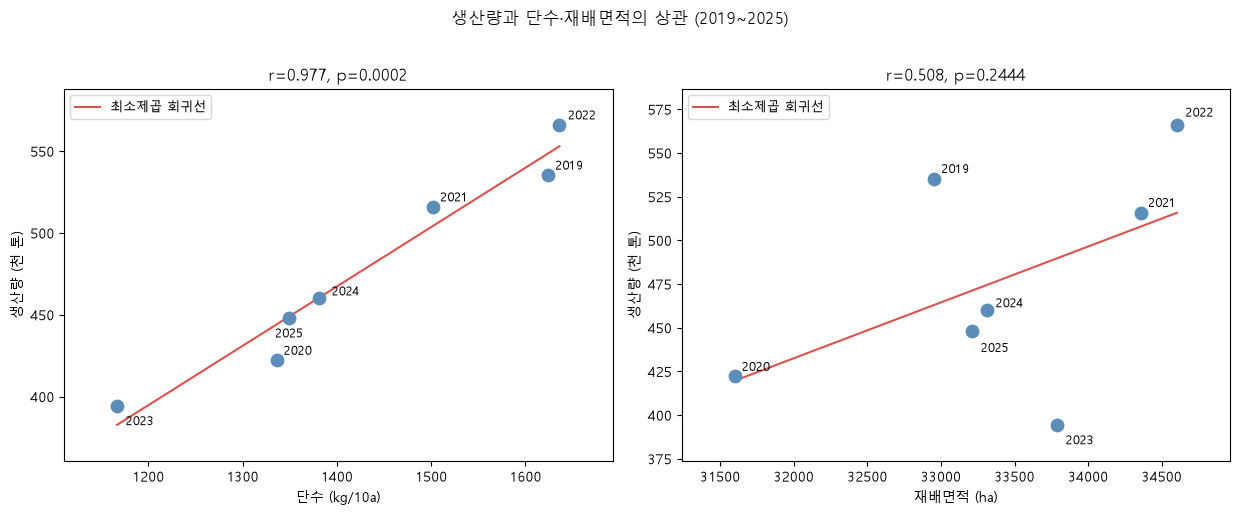

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
for ax, xv, lab in [(axes[0], d7['단수(kg/10a)'], '단수 (kg/10a)'),
                    (axes[1], d7['재배면적(ha)'], '재배면적 (ha)')]:
    r, pv = stats.pearsonr(xv, d7['생산량(천 톤)'])
    ax.scatter(xv, d7['생산량(천 톤)'], s=80, color='#5b8db8', zorder=3)
    b1, b0 = np.polyfit(xv, d7['생산량(천 톤)'], 1)
    xs = np.linspace(xv.min(), xv.max(), 50)
    ax.plot(xs, b0+b1*xs, '-', color='#d9534f', label='최소제곱 회귀선')
    ax.set_xlabel(lab); ax.set_ylabel('생산량 (천 톤)')
    ax.margins(0.12)
    ax.set_title(f'r={r:.3f}, p={pv:.4f}')
    off = ({2019:(5,4),2020:(5,4),2021:(5,4),2022:(6,4),2023:(6,-14),2024:(9,2),2025:(-10,-14)}
           if lab.startswith('단수') else
           {2019:(5,4),2020:(5,4),2021:(5,4),2022:(6,6),2023:(6,-14),2024:(6,2),2025:(6,-15)})
    for _, row in d7.iterrows():
        ax.annotate(int(row['연도']), (row['단수(kg/10a)'] if lab.startswith('단수') else row['재배면적(ha)'],
                    row['생산량(천 톤)']), fontsize=9, xytext=off[int(row['연도'])], textcoords='offset points')
    ax.legend(fontsize=9)
plt.suptitle('생산량과 단수·재배면적의 상관 (2019~2025)', y=1.02)
plt.tight_layout()
plt.savefig('figures/fig3_production_drivers.png', dpi=110, bbox_inches='tight')
plt.show()

**그래프에서 확인한 것:** 좌측(단수)에서 점들이 회귀선에 가깝게 몰려 있고(r=0.977), 우측(재배면적)에서는 흩어져 있다(r=0.508). 2023년(흉작)과 2022년(풍작)이 단수 축의 양 끝에서 생산량 격차를 만들었다.

![그림3](figures/fig3_production_drivers.png)

In [ ]:
# 기상 자료 수집 방법 기록 (Open-Meteo Historical Weather API, models=era5 명시)
# CSV가 이미 있으면 재다운로드하지 않고 검증만 수행한다.
import json, urllib.request, os

W_URL = ("https://archive-api.open-meteo.com/v1/archive?latitude={lat}&longitude={lon}"
         "&start_date=2019-01-01&end_date=2025-12-31&models=era5"
         "&daily=temperature_2m_mean,precipitation_sum&timezone=Asia%2FSeoul")
STATIONS = {'안동': (36.54, 128.73), '상주': (36.41, 128.16), '충주': (36.97, 127.93)}

if not os.path.exists('apple_region_weather_monthly_2019_2025.csv'):
    frames = []
    for name, (lat, lon) in STATIONS.items():
        with urllib.request.urlopen(W_URL.format(lat=lat, lon=lon), timeout=60) as r:
            d = pd.DataFrame(json.load(r)['daily']); d['지점'] = name
        frames.append(d)
    a = pd.concat(frames)
    a['time'] = pd.to_datetime(a['time']); a['연월'] = a['time'].dt.strftime('%Y-%m')
    mt = a.groupby(['연월','지점'])['temperature_2m_mean'].mean().reset_index(name='월평균기온_C')
    mp = a.groupby(['연월','지점'])['precipitation_sum'].sum().reset_index(name='월강수량_mm')
    m = pd.merge(mt, mp, on=['연월','지점'])
    m['연도'] = m['연월'].str[:4].astype(int); m['월'] = m['연월'].str[5:].astype(int)
    m.sort_values(['지점','연도','월']).to_csv('apple_region_weather_monthly_2019_2025.csv',
                                             index=False, encoding='utf-8-sig')
    print("재수집 완료")

wchk = pd.read_csv('apple_region_weather_monthly_2019_2025.csv')
print("수집 URL 템플릿:", W_URL)
print("좌표:", STATIONS, "| 시간대: Asia/Seoul | 모델: ERA5 재분석")
print("지점별 월 수:"); print(wchk.groupby('지점').size())
print("월별 지점 수 최소:", wchk.groupby(['연도','월']).size().min(), "(3이면 전월 커버)")

수집 URL 템플릿: https://archive-api.open-meteo.com/v1/archive?latitude={lat}&longitude={lon}&start_date=2019-01-01&end_date=2025-12-31&models=era5&daily=temperature_2m_mean,precipitation_sum&timezone=Asia%2FSeoul
좌표: {'안동': (36.54, 128.73), '상주': (36.41, 128.16), '충주': (36.97, 127.93)} | 시간대: Asia/Seoul | 모델: ERA5 재분석
지점별 월 수:
지점
상주    84
안동    84
충주    84
dtype: int64
월별 지점 수 최소: 3 (3이면 전월 커버)


## 8단계: 기상 자료를 결합한 단수 분석 (탐색적)

사과 주산지(경북 안동·상주, 충북 충주)의 2019~2025년 일별 기온·강수량을 [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api)에서 `models=era5`를 명시해 수집하고, 월별 CSV(`apple_region_weather_monthly_2019_2025.csv`)로 정리했다(3개 지점 × 84개월 = 252행, 일별 결측 0건).

**근거와 한계:** ERA5는 관측값을 모형으로 재구성한 재분석 자료로 실측과 다를 수 있고, 좌표 기반 자료라 관측소 실측이 아니다. 3개 지점의 평균이 전국 사과 재배지를 대표하지도 못한다. n=7이므로 결과는 탐색적 가설 수준이다. 단수는 기상 외에 품종·수령·병해·관리의 영향도 받으므로 아래 상관을 '기상의 효과'로 확장 해석하지 않는다.

In [18]:
# 기상 CSV 경로 — 파일이 없으면 인터넷에서 자동으로 내려받는다
WEATHER_PATH = r'C:/jkevin/DI-2/apple_region_weather_monthly_2019_2025.csv'

import os, json, urllib.request

if not os.path.exists(WEATHER_PATH):
    print("기상 CSV가 없어 인터넷에서 내려받습니다...")
    STATIONS = {'안동': (36.54, 128.73), '상주': (36.41, 128.16), '충주': (36.97, 127.93)}
    W_URL = ("https://archive-api.open-meteo.com/v1/archive?latitude={lat}&longitude={lon}"
             "&start_date=2019-01-01&end_date=2025-12-31&models=era5"
             "&daily=temperature_2m_mean,precipitation_sum&timezone=Asia%2FSeoul")
    frames = []
    for name, (lat, lon) in STATIONS.items():
        with urllib.request.urlopen(W_URL.format(lat=lat, lon=lon), timeout=60) as r:
            d = pd.DataFrame(json.load(r)['daily']); d['지점'] = name
        frames.append(d)
    a = pd.concat(frames)
    a['time'] = pd.to_datetime(a['time']); a['연월'] = a['time'].dt.strftime('%Y-%m')
    mt = a.groupby(['연월','지점'])['temperature_2m_mean'].mean().reset_index(name='월평균기온_C')
    mp = a.groupby(['연월','지점'])['precipitation_sum'].sum().reset_index(name='월강수량_mm')
    m = pd.merge(mt, mp, on=['연월','지점'])
    m['연도'] = m['연월'].str[:4].astype(int); m['월'] = m['연월'].str[5:].astype(int)
    m.sort_values(['지점','연도','월']).to_csv(WEATHER_PATH, index=False, encoding='utf-8-sig')
    print("기상 CSV를 새로 저장했습니다")

# d7이 없으면 3단계(prod)와 7단계 셀을 먼저 실행해야 한다
if 'd7' not in globals():
    raise NameError("d7이 없습니다. 3단계(생산량 구성)와 7단계(상관분석) 셀을 먼저 실행하세요")

w = pd.read_csv(WEATHER_PATH)
print("기상 자료 요약: 지점", sorted(w['지점'].unique()), "| 기간", w['연도'].min(), "-", w['연도'].max(),
      "| 행 수", len(w))
wg = w.groupby(['연도','월'])[['월평균기온_C','월강수량_mm']].mean().reset_index()
yrs = list(range(2019, 2026))

def agg(years, months, col, how):
    sub = wg[(wg['연도'].isin(years)) & (wg['월'].isin(months))]
    g = sub.groupby('연도')[col]
    return (g.sum() if how=='sum' else g.mean())

wx = pd.DataFrame({
    '개화기_4월_평균기온(°C)': agg(yrs, [4], '월평균기온_C', 'mean'),
    '생육기_5_8월_강수량(mm)': agg(yrs, [5,6,7,8], '월강수량_mm', 'sum'),
    '생육기_6_8월_평균기온(°C)': agg(yrs, [6,7,8], '월평균기온_C', 'mean'),
}).reset_index()
dd = d7[['연도','단수(kg/10a)']].merge(wx, on='연도')
dd

기상 CSV가 없어 인터넷에서 내려받습니다...
기상 CSV를 새로 저장했습니다
기상 자료 요약: 지점 ['상주', '안동', '충주'] | 기간 2019 - 2025 | 행 수 252


,연도,단수(kg/10a),개화기_4월_평균기온(°C),생육기_5_8월_강수량(mm),생육기_6_8월_평균기온(°C)
0,2019,1624.0,12.760000,483.933333,25.049211
1,2020,1336.0,11.830000,907.233333,25.193847
2,2021,1502.0,14.050000,751.433333,25.173823
3,2022,1636.0,14.956667,571.966667,25.766511
4,2023,1167.0,14.198889,1134.533333,26.015281
5,2024,1381.0,16.250000,659.066667,26.722521
6,2025,1349.0,14.291111,582.200000,26.911434


단수와 기상 변수의 피어슨 상관 (n=7, 비보정 p값):
단수 ~ 개화기_4월_평균기온(°C): r=-0.015, p=0.9752 (Bonferroni 보정 p≈1.000)
단수 ~ 생육기_5_8월_강수량(mm): r=-0.810, p=0.0274 (Bonferroni 보정 p≈0.082)
단수 ~ 생육기_6_8월_평균기온(°C): r=-0.431, p=0.3346 (Bonferroni 보정 p≈1.000)


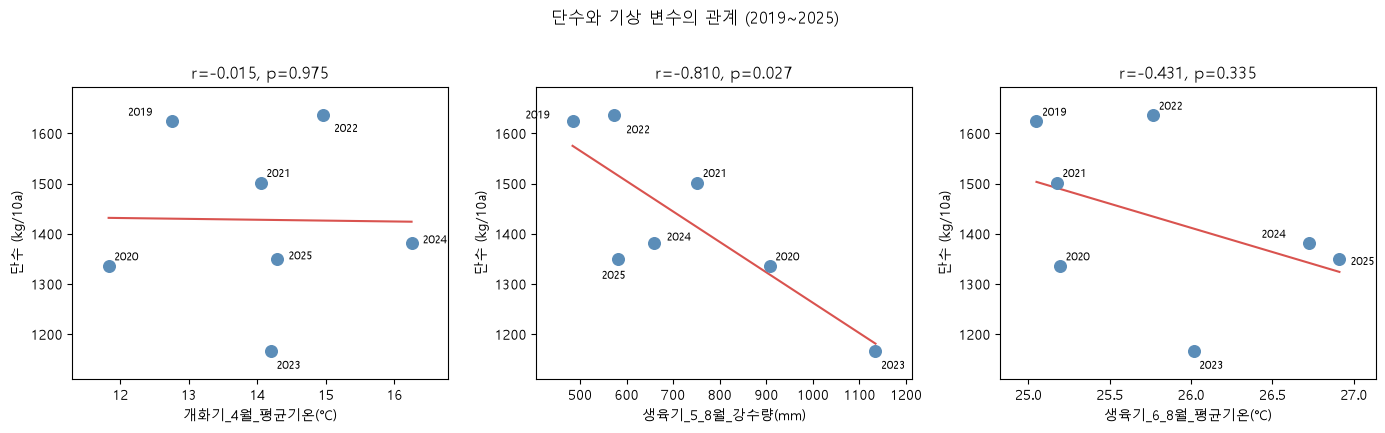

In [19]:
print("단수와 기상 변수의 피어슨 상관 (n=7, 비보정 p값):")
res = {}
for c in ['개화기_4월_평균기온(°C)','생육기_5_8월_강수량(mm)','생육기_6_8월_평균기온(°C)']:
    r, pv = stats.pearsonr(dd[c], dd['단수(kg/10a)'])
    res[c] = (r, pv)
    print(f"단수 ~ {c}: r={r:.3f}, p={pv:.4f} (Bonferroni 보정 p≈{min(1, pv*3):.3f})")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for j, (ax, c) in enumerate(zip(axes, ['개화기_4월_평균기온(°C)','생육기_5_8월_강수량(mm)','생육기_6_8월_평균기온(°C)'])):
    r, pv = stats.pearsonr(dd[c], dd['단수(kg/10a)'])
    ax.scatter(dd[c], dd['단수(kg/10a)'], s=70, color='#5b8db8', zorder=3)
    b1, b0 = np.polyfit(dd[c], dd['단수(kg/10a)'], 1)
    xs = np.linspace(dd[c].min(), dd[c].max(), 50)
    ax.plot(xs, b0+b1*xs, '-', color='#d9534f')
    ax.set_xlabel(c); ax.set_ylabel('단수 (kg/10a)')
    ax.margins(0.12)
    ax.set_title(f'r={r:.3f}, p={pv:.3f}')
    off = {0:{2019:(-32,4),2020:(4,4),2021:(4,4),2022:(8,-12),2023:(4,-13),2024:(8,0),2025:(8,0)},
           1:{2019:(-34,2),2020:(4,4),2021:(4,4),2022:(9,-13),2023:(4,-13),2024:(9,2),2025:(-12,-14)},
           2:{2019:(4,4),2020:(4,4),2021:(4,4),2022:(4,4),2023:(4,-13),2024:(-34,4),2025:(8,-4)}}[j]
    for _, row in dd.iterrows():
        ax.annotate(int(row['연도']), (row[c], row['단수(kg/10a)']), fontsize=8,
                    xytext=off[int(row['연도'])], textcoords='offset points')
plt.suptitle('단수와 기상 변수의 관계 (2019~2025)', y=1.02)
plt.tight_layout()
plt.savefig('figures/fig2_yield_weather.png', dpi=110, bbox_inches='tight')
plt.show()

**기상 결합 분석에 대한 나의 해석:**

- 단수와 생육기(5~8월) 강수량의 상관은 **r=−0.810, 비보정 p=0.027**다. 생육기 강수가 많았던 2020년(907mm)·2023년(1,135mm)에 단수가 낮았다(1,336·1,167kg/10a). 다만 세 변수를 탐색한 다중 검정이므로 단순 Bonferroni 보정을 적용하면 p≈0.082로 5% 수준을 넘는다. 그래서 나는 이 결과를 '통계적으로 유의하다'가 아니라 **'유망한 탐색적 가설'**로만 제시한다.
- 개화기(4월) 평균기온은 r=−0.015으로 이 표본에서 관계를 확정할 근거가 부족하다. 서리·저온 피해는 최저기온과 발생 시점에 따라 결정되므로 월평균기온으로 포착되지 않을 가능성을 나는 별도로 기록해 둔다.
- 생육기(6~8월) 평균기온은 r=−0.431, p=0.335로 유의하지 않다.
- 강수-단수의 음의 상관에 대한 생물학적 해석(일조 부족·병해)은 이 분석에서 확인된 것이 아니라 후속 검증이 필요한 가설이다.

![그림2](figures/fig2_yield_weather.png)

## 9단계: 결론

### 질문 1 — 잉여 사과가 있는가?

이 자료에는 잉여·폐기·미활용 물량을 직접 측정하는 항목이 없어서 나는 판단을 유보한다. 관측되는 것은 생산-출하 집계상 잔차(작기당 0.3~1.4천 톤)뿐이며, 출하량 자체가 실적과 전망이 섞인 조사치다. 잉여 여부는 소비량·가격·재고·가공수요 자료를 결합해야 판단할 수 있다.

### 질문 2 — 생산량을 줄여야 하는가?

이 자료만으로 생산량 축소를 권고할 근거는 없다. 2023년 흉작 이후 생산은 회복 중이고(2024년 460.1, 2025년 448.0천 톤) 12월 저장량도 전작과 비슷한 수준이다. 외부 정보를 함께 보면 1인당 소비량은 감소 전망(2026년 8.6kg → 2035년 8.1kg)이고 도매가격은 고공(2025년 86,687원/10kg)이어서([KIFC](https://www.foodandclimate.or.kr/food-security/commodity-outlook/apple/)), 수요 대비 공급 과잉 여부는 가격·소비 자료 없이는 결론할 수 없다. 또한 이 표본의 생산량 변동에는 면적보다 단수의 변화가 크게 동반됐으므로, 면적을 줄여도 작황에 따른 변동은 사라지지 않는다. **감산 권고는 유보하는 것이 자료에 충실한 결론**이다.

### 질문 3 — 출하되지 못한 사과는 어떤 과정을 거치는가?

월보에는 처우 정보가 없다. 한국사과연합회는 가격이 크게 하락할 때 물량 감축 수단으로 출하조절, 비정형과 분리, 가공용 전환(주스·사과즙), 산지폐기를 제시한다([동아일보, 2026.8.30](https://v.daum.net/v/20260830100152655)). 나는 이것을 '반드시 순서대로 거치는 절차'가 아니라, **물량의 상태·안전성·저장 여력에 따른 대안들**로 정리했다: 저장성이 높고 품질이 유지되면 저장 후 분할 출하하고, 상품성이 낮으면 선별 후 가공용으로 전환하며, 식용으로 활용할 수 없는 물량은 적정 처리(폐기·사료화 등) 경로를 거칠 수 있다. 품질이 낮다고 모두 식품 가공에 적합한 것도 아니다. 실제 처분 이력은 이 자료로 확인되지 않는다.

### 질문 4~5 — 생산 변동의 구조

생산량 변동은 단수(r=0.977)가 주도하고 재배면적(r=0.508, 유의 안 함)은 배경 요인이다. 단수는 생육기(5~8월) 강수량과 음의 상관(r=−0.810, 보정 후 유의성 약화)을 보였다.

## 향후 보완이 필요한 것 (내가 확인한 한계)

1. **소비·가격 자료 부족:** 잉여 판단의 핵심인 1인당 소비량, 도·소매 가격, 품질(대과 비중) 자료를 KAMIS·KREI 소비동향 자료와 결합해야 한다.
2. **가공·폐기 물량 자료 부족:** 미출하·가공용·폐기 물량의 실측 자료가 없다. 자조금·aT 실태조사를 확인할 필요가 있다.
3. **기상 자료의 정밀화:** ERA5 재분석 3개 지점이 아니라 기상청 관측값, 지역별(군 단위) 생산량, 개화기 최저기온·서리 일수, 생육기 일조시간을 결합해야 인과에 가까워진다.
4. **표본 수 확대:** 연도 7개는 상관분석에 부족하다. 2000년대 이후로 기간을 늘리고 지역 단위 패널로 만들면 신뢰도가 올라간다.
5. **출하량 정의 확인:** 월보 출하량의 작기 정의와 실적/전망 구분을 KREI 원문에서 문서로 확인해야 한다.
6. **2026년산 추적:** 2026년 10월 추정치(483.3천 톤)는 이후 호수에서 수정된다.